# Insertion base prediction

The full pipeline on one task: data, leakage check, training, evaluation,
attribution, export.

**The data is synthetic.** It comes from a rule in `crispr_attention.data`.
That is on purpose. Because the informative positions are known, attribution
can be scored against the right answer instead of only plotted.

**No biological claim is made here.** This notebook tests the pipeline.

**The rule.** The inserted base is a copy of the base four positions upstream
of the cut. Whether a site inserts at all depends on local context. So two
things have to be learned, and the classes are very imbalanced by design.
Motivated by van Overbeek et al. (2016) *Molecular Cell* and Lemos et al.
(2018) *PNAS*.

**Why the insertion rate depends on sequence.** Reads from one site share a
sequence but not an outcome. If every site inserted at the same rate, the best
per read guess would be the majority class and no model could beat it. Tying
the rate to sequence is what gives the model something to learn.
`bayes_ceiling` reports the limit.

## 1. Setup

In [1]:
import sys, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent               # repository root, when run from notebooks/
sys.path.insert(0, str(ROOT))
import crispr_attention as ca

DOCS, MODELS, EXAMPLES = ROOT / "docs", ROOT / "models", ROOT / "examples"
for d in (DOCS, MODELS, EXAMPLES):
    d.mkdir(exist_ok=True)

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

def savefig(fig, name):
    fig.savefig(DOCS / (name + ".png"))
    return fig

print("python", sys.version.split()[0], "| torch", torch.__version__, "| device", DEVICE)

python 3.12.3 | torch 2.14.1+cu130 | device cpu


## 2. The data

One group is one target site. Each site gives several reads. They share a
sequence and differ only by noise away from the cut. Labels vary within a
site, because repair is random.

Sites share a common flanking sequence. Only the region around the cut changes
between sites. Real amplicon libraries look like this. It also stops the model
identifying a site from its flanks.

In [2]:
X, y, groups, CLASSES, template_pos = ca.make_insertion_task(
    n_groups=2000, per_group=12,
    length=40, cut=20, seed=SEED)

WINDOW = (template_pos, template_pos + 2)        # informative positions, known from the generating rule

print("reads       ", format(len(X), ","))
print("target sites", format(len(np.unique(groups)), ","))
print("length      ", X.shape[1], "bp")
print("classes     ", CLASSES)
print("templating position ", template_pos)
print("informative  positions", WINDOW[0], "to", WINDOW[1] - 1,
      "(the templating base and the one beside it)")
print("\nexample read:", ca.decode(X[0]))

reads        24,000
target sites 2,000
length       40 bp
classes      ['no_indel', 'ins_A', 'ins_C', 'ins_G', 'ins_T']
templating position  16
informative  positions 16 to 17 (the templating base and the one beside it)

example read: TGGCCAAACAAAAGGGCGTCCTTTCGTGTGGCATAGACCC


### Baseline and ceiling

Three numbers go together.

- **Majority baseline**: accuracy from always predicting the most common
  class. The model has to beat this.
- **Group ceiling**: the best accuracy any per read model can reach, since
  reads at a site share a sequence but not a label. This is the target, not 1.0.
- **Class support**: macro F1 is won or lost on the rare classes.

In [3]:
counts = pd.Series(y).value_counts().sort_index()
display(pd.DataFrame({"class": CLASSES, "reads": counts.values,
                      "fraction": (counts.values / len(y)).round(4)}))

baseline = counts.max() / len(y)
ceiling = ca.bayes_ceiling(y, groups)
print(f"majority class baseline : {baseline:.4f}   ('{CLASSES[counts.idxmax()]}')")
print(f"group ceiling           : {ceiling:.4f}")
print(f"headroom available      : {ceiling - baseline:.4f}")

,class,reads,fraction
0,no_indel,18722,0.7801
1,ins_A,1390,0.0579
2,ins_C,1411,0.0588
3,ins_G,1280,0.0533
4,ins_T,1197,0.0499


majority class baseline : 0.7801   ('no_indel')
group ceiling           : 0.9087
headroom available      : 0.1287


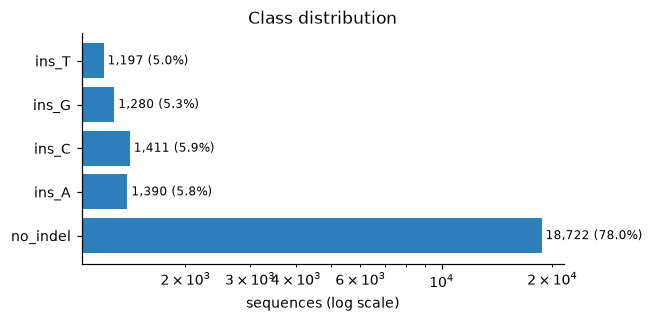

In [4]:
savefig(ca.plots.class_distribution(y, CLASSES), "ins_class_distribution");

## 3. Leakage check

Reads from one site are near copies. Splitting rows at random puts copies in
both train and test, so the score measures memory rather than generalisation.

This is worst when a few sites are sequenced deeply, so that is the case
tested below. Same data, same settings. Only the split differs.

In [5]:
def random_row_split(n, train=0.7, val=0.15, seed=0):
    idx = np.random.default_rng(seed).permutation(n)
    a, b = int(n * train), int(n * (train + val))
    return idx[:a], idx[a:b], idx[b:]

# A few sites, sequenced deeply: the regime where leakage does the most damage.
Xl, yl, gl, _, _ = ca.make_insertion_task(n_groups=60, per_group=300,
                                length=40, cut=20, seed=SEED)

leak = {}
for label, (tr, va, te) in [("row level (wrong)", random_row_split(len(Xl), seed=SEED)),
                            ("by site (correct)", ca.group_split(gl, seed=SEED))]:
    m = ca.AttentionBiLSTM(num_classes=len(CLASSES))
    m, _ = ca.fit(m, Xl[tr], yl[tr], Xl[va], yl[va], epochs=25, patience=5,
                  weight_decay=1e-4, device=DEVICE, verbose=False)
    r = ca.evaluate(yl[te], ca.predict(m, Xl[te], device=DEVICE),
                    y_train=yl[tr], target_names=CLASSES)
    seen = {Xl[i].tobytes() for i in tr}
    leak[label] = {"accuracy": round(r["accuracy"], 4),
                   "macro F1": round(r["macro_f1"], 4),
                   "majority baseline accuracy": round(r["baseline"]["accuracy"], 4),
                   "test reads also seen in train": f"{np.mean([Xl[i].tobytes() in seen for i in te]):.0%}"}

display(pd.DataFrame(leak))
print(f"macro F1 inflated by a factor of "
      f"{leak['row level (wrong)']['macro F1'] / max(leak['by site (correct)']['macro F1'], 1e-9):.1f}"
      f" by splitting rows instead of sites")

/home/claude/scnb/env312/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,row level (wrong),by site (correct)
accuracy,0.8048,0.7322
macro F1,0.6958,0.485
majority baseline accuracy,0.7826,0.7189
test reads also seen in train,81%,0%


macro F1 inflated by a factor of 1.4 by splitting rows instead of sites


The row split looks like a working model. The correct split on the same data
shows what is really there.

Everything from section 4 on uses the larger dataset from section 2, split by
site.

## 4. The correct split, by target site

Whole sites go to one side of the split. The assertion and the duplicate count
below confirm it worked.

In [6]:
train, val, test = ca.group_split(groups, train=0.7, val=0.15, seed=SEED)

gtr, gva, gte = (set(groups[i]) for i in (train, val, test))
assert not (gtr & gva) and not (gtr & gte) and not (gva & gte), "site appears in two splits"

train_seqs = {X[i].tobytes() for i in train}
dup_group = np.mean([X[i].tobytes() in train_seqs for i in test])

display(pd.DataFrame({"split": ["train", "validation", "test"],
                      "sites": [len(gtr), len(gva), len(gte)],
                      "reads": [len(train), len(val), len(test)]}))
print("no site appears in two splits: OK")
print(f"test reads whose exact sequence also appears in train: {dup_group:.1%}")

,split,sites,reads
0,train,1400,16800
1,validation,300,3600
2,test,300,3600


no site appears in two splits: OK
test reads whose exact sequence also appears in train: 0.0%


## 5. The model

A bidirectional LSTM with attention pooling (Bahdanau et al., 2015). Attention
gives one weight per position, which is what makes section 9 possible.

Two things that are easy to get wrong:

- **Six tokens in the vocabulary.** Four bases, N, and padding. Treating whole
  sequences as tokens gives a lookup table that can only memorise.
- **Padding is masked before the attention softmax.** Section 9 checks this
  rather than assuming it.

In [7]:
model = ca.AttentionBiLSTM(num_classes=len(CLASSES), embed_dim=32, hidden_dim=64,
                           attn_dim=64, dropout=0.3, use_positional=True)
print(model)
print("\ntrainable parameters:", format(model.n_parameters(), ","))
print("training reads      :", format(len(train), ","))
print("training sites      :", format(len(gtr), ","),
      " <- the real sample size")

AttentionBiLSTM(
  (embedding): Embedding(6, 32, padding_idx=0)
  (pos): PositionalEncoding()
  (lstm): LSTM(32, 64, batch_first=True, bidirectional=True)
  (attn): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=5, bias=True)
)

trainable parameters: 59,334
training reads      : 16,800
training sites      : 1,400  <- the real sample size


## 6. Training

Class weighted loss, because the classes are imbalanced. Early stopping on
validation macro F1 rather than accuracy, which under imbalance would pick a
model that ignores the rare classes. Weight decay limits memorising sites. The
test set is used once.

In [8]:
model, history = ca.fit(model, X[train], y[train], X[val], y[val],
                        epochs=40, patience=6, batch_size=128, lr=1e-3,
                        weight_decay=1e-4, class_weight=True,
                        device=DEVICE, verbose=True)

epoch   1  train loss 1.0223  val loss 0.4425  val macro F1 0.6153


epoch   2  train loss 0.3437  val loss 0.3009  val macro F1 0.6135


epoch   3  train loss 0.3160  val loss 0.2883  val macro F1 0.6134


epoch   4  train loss 0.2954  val loss 0.2746  val macro F1 0.7157


epoch   5  train loss 0.2938  val loss 0.2753  val macro F1 0.6903


...

epoch   8  train loss 0.2865  val loss 0.2830  val macro F1 0.7894


epoch   9  train loss 0.2880  val loss 0.2785  val macro F1 0.7587


epoch  10  train loss 0.2857  val loss 0.2746  val macro F1 0.7856


epoch  11  train loss 0.2826  val loss 0.2842  val macro F1 0.7560


epoch  12  train loss 0.2804  val loss 0.2747  val macro F1 0.7778
early stopping at epoch 12, best val macro F1 0.8142


best epoch 6 of 12, validation macro F1 0.8142


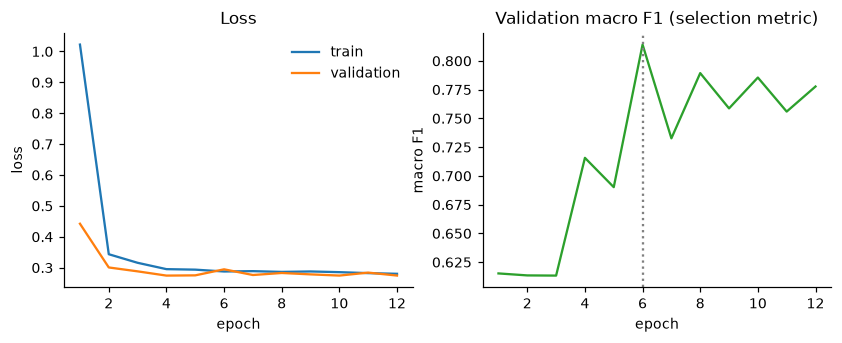

In [9]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(h.epoch, h.train_loss, label="train")
ax[0].plot(h.epoch, h.val_loss, label="validation")
ax[0].set(xlabel="epoch", ylabel="loss", title="Loss")
ax[0].legend(frameon=False)
best = int(h.val_macro_f1.idxmax()) + 1
ax[1].plot(h.epoch, h.val_macro_f1, color="tab:green")
ax[1].axvline(best, ls=":", color="grey")
ax[1].set(xlabel="epoch", ylabel="macro F1",
          title="Validation macro F1 (selection metric)")
savefig(fig, "ins_training_curves")
print(f"best epoch {best} of {len(h)}, validation macro F1 {h.val_macro_f1.max():.4f}")

## 7. Read level evaluation

Reported against the majority baseline and the group ceiling. Accuracy alone
cannot separate a model that learned the rule from one that learned the class
frequencies.

In [10]:
pred = ca.predict(model, X[test], device=DEVICE)
proba = ca.predict_proba(model, X[test], device=DEVICE)
res = ca.evaluate(y[test], pred, y_train=y[train], target_names=CLASSES)

print(ca.summary(res))
won = (res["accuracy"] - res["baseline"]["accuracy"]) / (ceiling - res["baseline"]["accuracy"])
print(f"\ngroup ceiling             : {ceiling:.4f}")
print(f"share of headroom won     : {won:.1%}")
print(f"macro F1 over baseline    : {res['macro_f1'] / res['baseline']['macro_f1']:.1f}x")

accuracy           0.8781
balanced accuracy  0.8517
macro F1           0.7935
weighted F1        0.8836

majority baseline ('0')
  accuracy         0.7806
  macro F1         0.1754

beats baseline on accuracy : True
beats baseline on macro F1 : True

group ceiling             : 0.9087
share of headroom won     : 76.1%
macro F1 over baseline    : 4.5x


### Per class metrics

Macro F1 is the mean of the F1 column, so this shows which classes carry the
score.

In [11]:
from sklearn.metrics import precision_recall_fscore_support
pr, rc, f1, sup = precision_recall_fscore_support(
    y[test], pred, labels=range(len(CLASSES)), zero_division=0)
display(pd.DataFrame({"class": CLASSES, "precision": pr.round(3), "recall": rc.round(3),
                      "f1": f1.round(3), "support": sup,
                      "prevalence": (sup / sup.sum()).round(4)}))

,class,precision,recall,f1,support,prevalence
0,no_indel,0.955,0.885,0.919,2810,0.7806
1,ins_A,0.750,0.764,0.757,165,0.0458
2,ins_C,0.591,0.909,0.716,296,0.0822
3,ins_G,0.819,0.827,0.823,202,0.0561
4,ins_T,0.661,0.874,0.753,127,0.0353


### Confusion matrix

Row normalised. Each row is the recall of that class and shows where its
errors go.

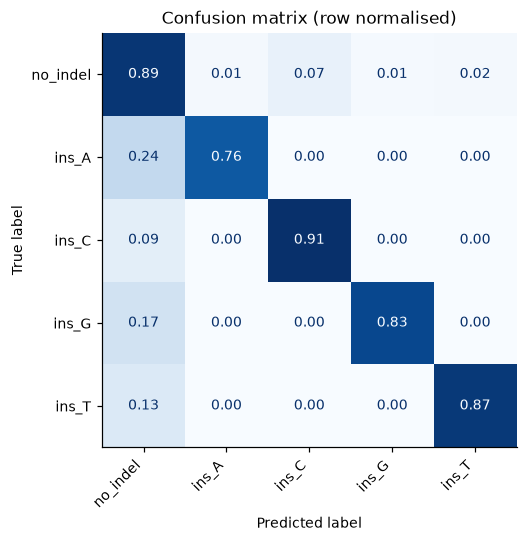

In [12]:
savefig(ca.plots.confusion(res["confusion_matrix"], CLASSES, normalise=True),
        "ins_confusion_matrix");

### Precision-recall curve per class

Precision-recall, not ROC. Under heavy imbalance a ROC curve looks good almost
regardless of the model (Saito and Rehmsmeier, 2015). Each curve is compared
with its own class prevalence, which is its chance level.

,class,n_positive,average_precision,chance,lift
0,no_indel,2810,0.947954,0.780556,1.214461
1,ins_A,165,0.647651,0.045833,14.130559
2,ins_C,296,0.739192,0.082222,8.990175
3,ins_G,202,0.732493,0.056111,13.054324
4,ins_T,127,0.687433,0.035278,19.486291


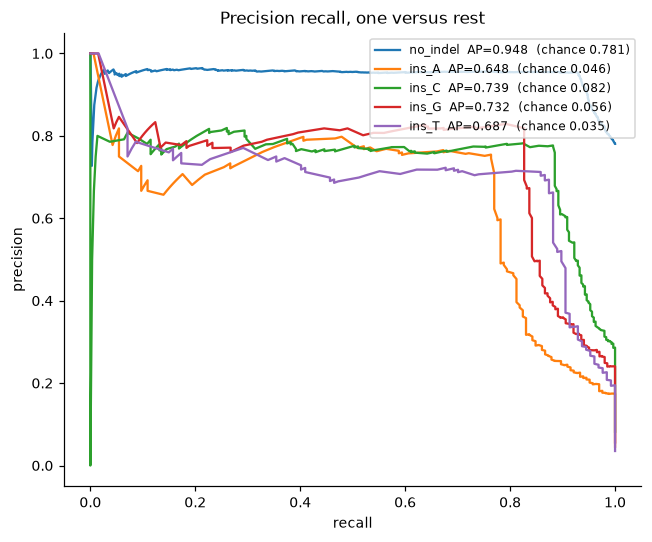

In [13]:
fig, ap_rows = ca.plots.pr_curves(y[test], proba, CLASSES)
savefig(fig, "ins_pr_curves")
display(pd.DataFrame(ap_rows))

## 8. Site level evaluation

Published models predict the outcome distribution at a site, not a class for
one read (inDelphi, FORECasT). A per read label is one draw from that
distribution, so much of the per read error cannot be removed by any model.

Here the predicted probabilities are averaged over a site's reads and compared
with the observed frequencies.

In [14]:
site = ca.site_evaluate(proba, y[test], groups[test], n_classes=len(CLASSES))
print(ca.site_summary(site))
print("\nread level, for comparison: "
      f"accuracy {res['accuracy']:.4f}, macro F1 {res['macro_f1']:.4f}")

target sites               300  (median 12 reads each)
modal outcome accuracy     0.9567
pooled Pearson r           0.9015
mean within site Pearson r 0.9232
mean absolute error        0.0912

read level, for comparison: accuracy 0.8781, macro F1 0.7935


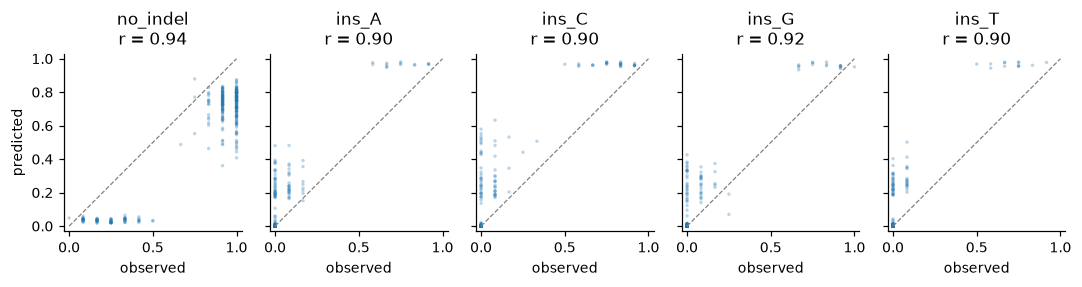

In [15]:
savefig(ca.plots.predicted_vs_observed(site["predicted"], site["observed"], CLASSES),
        "ins_site_predicted_vs_observed");

## 9. What the model uses

Accuracy does not say whether the model found the rule or a shortcut. The
informative positions are known here, so attribution can be scored.

Three methods, because they fail in different ways.

- **Attention**, read from the pooling layer. Cheap, but not an explanation on
  its own (Jain and Wallace, 2019).
- **Saliency**, the gradient at the input (Simonyan et al., 2014). Noisy.
- **Integrated gradients**, the gradient averaged along a path from a baseline
  (Sundararajan et al., 2017). Satisfies completeness, so trust it when the
  three disagree.

Agreement across all three is the result. One method alone is not.

In [16]:
attn = ca.interpret.attention_weights(model, X[test], device=DEVICE)
sal = ca.interpret.saliency(model, X[test], pred, device=DEVICE)
ig = ca.interpret.integrated_gradients(model, X[test], pred, steps=32, device=DEVICE)

print("attention rows sum to", np.unique(attn.sum(1).round(4)))
print("attention mass on padded positions:",
      attn[:, (X[test] == 0).any(0)].sum(), "(masked, so exactly 0)")

attention rows sum to [1.]
attention mass on padded positions: 0.0 (masked, so exactly 0)


In [17]:
METHODS = [("attention", attn), ("saliency", sal), ("integrated gradients", ig)]

rows = []
for name, s in METHODS:
    m = s.mean(0)
    p = m / m.sum()
    rows.append({"method": name,
                 "enrichment": round(ca.interpret.enrichment(p, WINDOW), 2),
                 "peak_position": int(m.argmax()),
                 "peak_inside_window": bool(WINDOW[0] <= m.argmax() < WINDOW[1]),
                 "mass_inside_window": round(float(p[WINDOW[0]:WINDOW[1]].sum()), 3)})
verdict = pd.DataFrame(rows)
display(verdict)

span = WINDOW[1] - WINDOW[0]
print(f"informative window: positions {WINDOW[0]} to {WINDOW[1] - 1} "
      f"({span} of {X.shape[1]} positions, so {span / X.shape[1]:.1%} of the sequence)")
print(f"{int(verdict.peak_inside_window.sum())} of {len(verdict)} methods peak inside it")

a = verdict.set_index("method").loc["attention"]
g = verdict.set_index("method").loc[["saliency", "integrated gradients"]]
if not a.peak_inside_window and g.peak_inside_window.all():
    print("\nATTENTION DISAGREES WITH THE GRADIENT METHODS.")
    print("Attention peaks outside the informative window while both gradient")
    print("methods peak inside it. The gradient methods are the ones to believe:")
    print("they measure how the output changes when the input changes, whereas")
    print("attention only reports where the pooling layer took its weighted mean")
    print("from, after the recurrent layer had already mixed context across")
    print("positions (Jain and Wallace, 2019).")
elif verdict.peak_inside_window.all():
    print("\nAll three methods agree, and all three peak inside the window the")
    print("generating rule made informative. That agreement is the result;")
    print("any one of them alone would not be.")

,method,enrichment,peak_position,peak_inside_window,mass_inside_window
0,attention,1592.68,16,True,0.988
1,saliency,20.33,16,True,0.517
2,integrated gradients,23.73,16,True,0.555


informative window: positions 16 to 17 (2 of 40 positions, so 5.0% of the sequence)
3 of 3 methods peak inside it

All three methods agree, and all three peak inside the window the
generating rule made informative. That agreement is the result;
any one of them alone would not be.


### Reading that table

All three methods agree, and all three peak on the templating position. The
window is 2 of 40 positions, so 5% of the sequence, and attention puts far
more weight there than a flat profile would.

Agreement across three methods that fail in different ways is the result. The
deletion notebook shows the opposite case, where attention and the gradient
methods disagree on a model that works.

The difference is the shape of the feature. An inserted base is set by one
position, so there is somewhere to concentrate. A microhomology length is a
comparison between positions, and there is not.

### The three methods side by side

Each profile is the mean over test reads, scaled to sum to one. The shaded band
is the informative window.

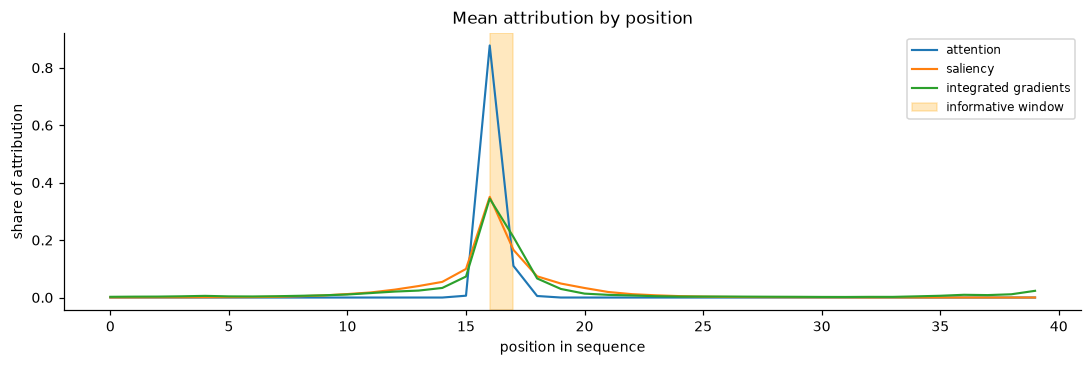

In [18]:
savefig(ca.plots.profile_comparison(
    {"attention": attn.mean(0), "saliency": sal.mean(0),
     "integrated gradients": ig.mean(0)}, highlight=WINDOW),
    "ins_attribution_comparison");

### Positional importance by class

The profiles above average over all reads, which can hide a model that uses
different positions for different outcomes.

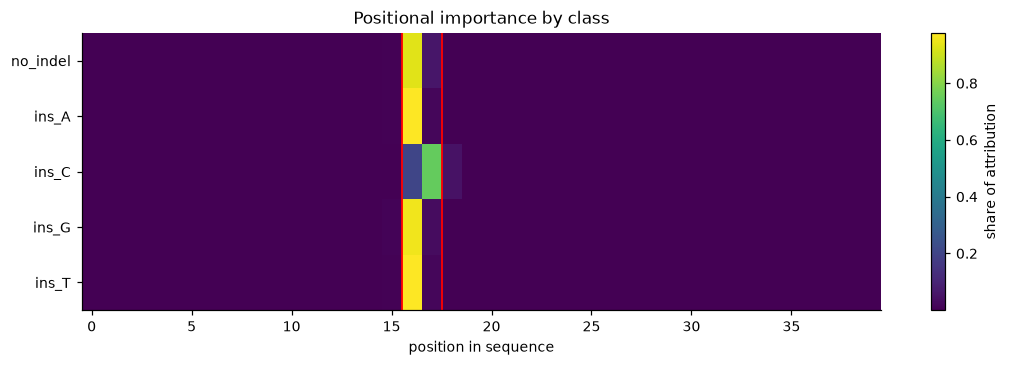

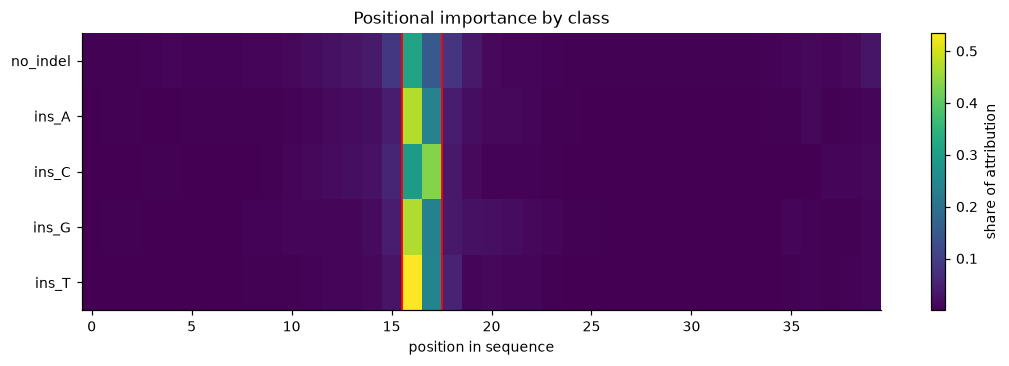

In [19]:
prof_attn = ca.interpret.per_class_profile(attn, y[test], len(CLASSES))
prof_ig = ca.interpret.per_class_profile(ig, y[test], len(CLASSES))

savefig(ca.plots.position_heatmap(prof_attn, CLASSES, highlight=WINDOW),
        "ins_position_heatmap_attention")
savefig(ca.plots.position_heatmap(prof_ig, CLASSES, highlight=WINDOW),
        "ins_position_heatmap_ig");

In [20]:
display(pd.DataFrame({
    "class": CLASSES,
    "attention_enrichment": [round(ca.interpret.enrichment(prof_attn[c], WINDOW), 2)
                             for c in range(len(CLASSES))],
    "ig_enrichment": [round(ca.interpret.enrichment(prof_ig[c], WINDOW), 2)
                      for c in range(len(CLASSES))],
    "top_attended_position": prof_attn.argmax(1),
    "top_ig_position": prof_ig.argmax(1),
}))

,class,attention_enrichment,ig_enrichment,top_attended_position,top_ig_position
0,no_indel,2153.59,16.54,16,16
1,ins_A,2484.30,46.69,16,16
2,ins_C,376.63,50.89,17,17
3,ins_G,2175.41,45.68,16,16
4,ins_T,3696.47,66.48,16,16


### Which base, at which position

The profiles say where the model looks. This says what it finds there:
integrated gradients split by the base present at each position.

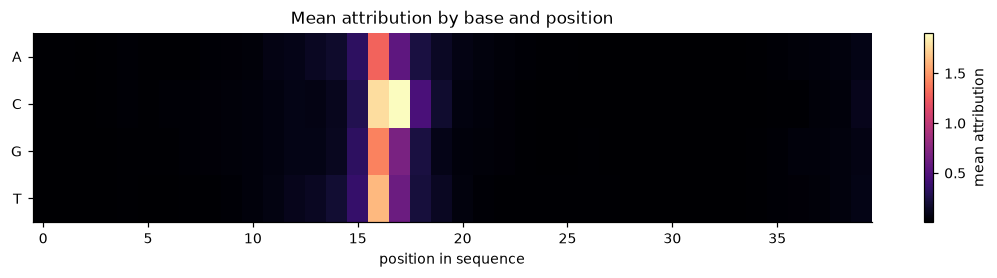

In [21]:
savefig(ca.plots.nucleotide_importance(X[test], ig), "ins_nucleotide_importance");

## 10. Does this survive a change of seed?

A positional claim from one run is a claim about one random initialisation.
Below, the model is refit on four seeds with the data and settings fixed,
recording performance and where each method peaked.

This decides whether the heatmaps above can be quoted.

In [22]:
stability = []
for s in range(4):
    msd = ca.AttentionBiLSTM(num_classes=len(CLASSES))
    msd, _ = ca.fit(msd, X[train], y[train], X[val], y[val], epochs=40, patience=6,
                    weight_decay=1e-4, device=DEVICE, seed=s, verbose=False)
    p_s = ca.predict(msd, X[test], device=DEVICE)
    pb_s = ca.predict_proba(msd, X[test], device=DEVICE)
    r_s = ca.evaluate(y[test], p_s, y_train=y[train], target_names=CLASSES)
    st_s = ca.site_evaluate(pb_s, y[test], groups[test], n_classes=len(CLASSES))
    row = {"seed": s, "accuracy": round(r_s["accuracy"], 4),
           "macro_f1": round(r_s["macro_f1"], 4),
           "site_r": round(st_s["pooled_pearson_r"], 4)}
    for nm, sc in [("attention", ca.interpret.attention_weights(msd, X[test], device=DEVICE)),
                   ("saliency", ca.interpret.saliency(msd, X[test], p_s, device=DEVICE)),
                   ("ig", ca.interpret.integrated_gradients(msd, X[test], p_s, steps=16,
                                                            device=DEVICE))]:
        prof = sc.mean(0)
        row[nm + "_enr"] = round(ca.interpret.enrichment(prof, WINDOW), 2)
        row[nm + "_peak"] = int(prof.argmax())
    stability.append(row)

stab = pd.DataFrame(stability)
display(stab)

,seed,accuracy,macro_f1,site_r,attention_enr,attention_peak,saliency_enr,saliency_peak,ig_enr,ig_peak
0,0,0.8908,0.8066,0.8901,3896.19,16,13.47,16,18.75,16
1,1,0.9003,0.8098,0.9095,8929.40,16,15.18,16,25.43,17
2,2,0.8972,0.8033,0.9039,1598.29,16,19.27,16,27.39,16
3,3,0.8764,0.7846,0.8911,724.72,16,19.30,16,30.38,16


In [23]:
spread = {nm: stab[nm + "_enr"].max() / max(stab[nm + "_enr"].min(), 1e-9)
          for nm in ("attention", "saliency", "ig")}
hits = {nm: int(stab[nm + "_peak"].between(WINDOW[0], WINDOW[1] - 1).sum())
        for nm in ("attention", "saliency", "ig")}

print("performance is stable across seeds:" if stab.macro_f1.std() < 0.05
      else "performance itself varies across seeds:")
print(f"  macro F1 {stab.macro_f1.min():.4f} to {stab.macro_f1.max():.4f}"
      f"   site r {stab.site_r.min():.4f} to {stab.site_r.max():.4f}")

print()
print(f"attribution, against the informative window "
      f"(positions {WINDOW[0]} to {WINDOW[1] - 1}):")
for nm in ("attention", "saliency", "ig"):
    print(f"  {nm:<10} peak inside on {hits[nm]}/{len(stab)} seeds,"
          f"  enrichment {stab[nm + '_enr'].min():>8.2f} to {stab[nm + '_enr'].max():>8.2f}"
          f"  ({spread[nm]:.1f}x range)")

reliable = [nm for nm in ("attention", "saliency", "ig") if hits[nm] == len(stab)]
unreliable = [nm for nm in ("attention", "saliency", "ig") if hits[nm] < len(stab)]
print()
if unreliable:
    print("NOT a stable basis for a positional claim: " + ", ".join(unreliable))
    print("(the peak leaves the informative window on at least one seed, while")
    print(" accuracy barely moves, so no performance metric would warn you)")
if reliable:
    print("stable across every seed: " + ", ".join(reliable))

performance is stable across seeds:
  macro F1 0.7846 to 0.8098   site r 0.8901 to 0.9095

attribution, against the informative window (positions 16 to 17):
  attention  peak inside on 4/4 seeds,  enrichment   724.72 to  8929.40  (12.3x range)
  saliency   peak inside on 4/4 seeds,  enrichment    13.47 to    19.30  (1.4x range)
  ig         peak inside on 4/4 seeds,  enrichment    18.75 to    30.38  (1.6x range)

stable across every seed: attention, saliency, ig


**How to read this.** Performance barely moves across seeds, so those numbers
can be quoted as they stand.

All three methods keep their peak on the templating position on every seed.
The attention enrichment swings over a wide range, but only because the
denominator, the attention left for the other 38 positions, is near zero. The
peak does not move, and the peak is what the claim rests on.

The deletion notebook runs the same check and gets the opposite answer. Same
architecture, different feature shape. That is why the check is run per task
rather than carried over.

## 11. Export and command line inference

A model that only exists in a notebook is not deployed. The checkpoint below
carries the weights, the constructor arguments, the class names, the window
length and the test metrics. `predict.py` loads it and takes CSV or FASTA.

In [24]:
ckpt = MODELS / "ins_model.pt"
torch.save({
    "state_dict": model.state_dict(),
    "model_kwargs": dict(embed_dim=32, hidden_dim=64, attn_dim=64,
                         dropout=0.3, use_positional=True),
    "classes": CLASSES,
    "seq_length": int(X.shape[1]),
    "task": "ins",
    "informative_window": list(WINDOW),
    "read_metrics": {k: float(res[k]) for k in
                     ("accuracy", "macro_f1", "weighted_f1", "balanced_accuracy")},
    "majority_baseline_accuracy": float(res["baseline"]["accuracy"]),
    "group_ceiling_accuracy": float(ceiling),
    "site_metrics": {k: float(site[k]) for k in
                     ("modal_accuracy", "pooled_pearson_r", "mean_absolute_error")},
}, ckpt)
print(ckpt.name, f"{ckpt.stat().st_size / 1024:.0f} KB")

ins_model.pt 302 KB


In [25]:
example = EXAMPLES / "ins_sequences.csv"
pick = np.random.default_rng(1).choice(test, 8, replace=False)
pd.DataFrame({"id": [f"site{groups[i]}_read{i}" for i in pick],
              "sequence": [ca.decode(X[i]) for i in pick],
              "true_class": [CLASSES[y[i]] for i in pick]}).to_csv(example, index=False)

run = subprocess.run([sys.executable, "predict.py",
                      "--model", f"models/{ckpt.name}",
                      "--input", f"examples/{example.name}",
                      "--id-col", "id",
                      "--output", "examples/ins_predictions.csv"],
                     cwd=ROOT, capture_output=True, text=True)
print(run.stdout or run.stderr)

wrote 8 predictions to examples/ins_predictions.csv
                id predicted_class  confidence  top_attended_position  p_no_indel  p_ins_A  p_ins_C  p_ins_G  p_ins_T
site1906_read22881        no_indel      0.6184                     16      0.6184   0.3771   0.0017   0.0014   0.0014
 site856_read10280           ins_C      0.9603                     17      0.0390   0.0003   0.9603   0.0002   0.0002
    site51_read617           ins_T      0.9679                     16      0.0317   0.0001   0.0001   0.0001   0.9679
site1906_read22879        no_indel      0.6184                     16      0.6184   0.3771   0.0017   0.0014   0.0014
site1648_read19785        no_indel      0.7957                     16      0.7957   0.0022   0.1993   0.0014   0.0013



In [26]:
out = pd.read_csv(EXAMPLES / "ins_predictions.csv")
truth = pd.read_csv(EXAMPLES / "ins_sequences.csv")[["id", "true_class"]]
display(out.merge(truth, on="id"))
print("the model expects the cut at position 20 of a 40 bp window; "
      "sequences windowed any other way will score as noise")

,id,predicted_class,confidence,top_attended_position,p_no_indel,p_ins_A,p_ins_C,p_ins_G,p_ins_T,true_class
0,site1906_read22881,no_indel,0.6184,16,0.6184,0.3771,0.0017,0.0014,0.0014,no_indel
1,site856_read10280,ins_C,0.9603,17,0.0390,0.0003,0.9603,0.0002,0.0002,ins_C
2,site51_read617,ins_T,0.9679,16,0.0317,0.0001,0.0001,0.0001,0.9679,no_indel
3,site1906_read22879,no_indel,0.6184,16,0.6184,0.3771,0.0017,0.0014,0.0014,no_indel
4,site1648_read19785,no_indel,0.7957,16,0.7957,0.0022,0.1993,0.0014,0.0013,no_indel
5,site247_read2966,no_indel,0.6189,16,0.6189,0.0015,0.0019,0.3724,0.0053,no_indel
6,site1527_read18326,no_indel,0.8235,16,0.8235,0.0025,0.1712,0.0016,0.0012,no_indel
7,site943_read11319,no_indel,0.6145,16,0.6145,0.0075,0.0020,0.3754,0.0006,no_indel


the model expects the cut at position 20 of a 40 bp window; sequences windowed any other way will score as noise


## 12. What this notebook shows

**Shown.**

- The pipeline runs end to end: data, split by site, training with early
  stopping, evaluation at read and site level against a baseline and a
  ceiling, three attribution methods, and a working command line predictor.
- Row level splitting inflates the score. Measured, not asserted.
- Padded positions get exactly zero attention.
- Attribution is scored against known positions, not only plotted.

**Not shown.**

- Nothing about repair biology. The rule was written by hand.
- Nothing about real sequencing data. Real reads need windowing on the cut in
  reference coordinates, one left alignment convention for indels, a distance
  cutoff, and the target site as the unit of learning. The README lists these.
- Attention is reported as attention, not as a mechanism.